# 📐 Week 5 — Linear Algebra Applied to Student Habits Dataset

**Hack-o-Week | Semester V 2026-27**

---

## Topics Covered
| Concept | What We Do |
|---|---|
| **Vectors** | Represent each student as a feature vector |
| **Matrices** | Dataset as a matrix; transpose, covariance |
| **Dot Product** | Measure similarity; linear prediction |
| **Eigenvalues** | PCA — directions of maximum variance |

> **Dataset**: `student_habits_performance.csv` — 1000 students, target: `exam_score`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 12
sns.set_theme(style="darkgrid")
print("Libraries loaded!")

Libraries loaded!


## Load & Prepare the Dataset

In [2]:
df = pd.read_csv("../Week-3/student_habits_performance.csv")
numeric_cols = [
    "study_hours_per_day","social_media_hours","netflix_hours",
    "attendance_percentage","sleep_hours","mental_health_rating",
    "exercise_frequency","exam_score"
]
df_num = df[numeric_cols].dropna()
print(f"Shape: {df_num.shape}")
df_num.head()

Shape: (1000, 8)


,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,mental_health_rating,exercise_frequency,exam_score
0,0.0,1.2,1.1,85.0,8.0,8,6,56.2
1,6.9,2.8,2.3,97.3,4.6,8,6,100.0
2,1.4,3.1,1.3,94.8,8.0,1,1,34.3
3,1.0,3.9,1.0,71.0,9.2,1,4,26.8
4,5.0,4.4,0.5,90.9,4.9,1,3,66.4


---
## 1. Vectors — Each Student as a Feature Vector

Each student is a vector in 8-dimensional space:
$$\vec{s} = [\text{study\_hrs},\ \text{social\_media},\ \text{netflix},\ \text{attendance},\ \text{sleep},\ \text{mental\_health},\ \text{exercise},\ \text{exam\_score}]$$

Student 1 feature vector:
  study_hours_per_day          = 0.00
  social_media_hours           = 1.20
  netflix_hours                = 1.10
  attendance_percentage        = 85.00
  sleep_hours                  = 8.00
  mental_health_rating         = 8.00
  exercise_frequency           = 6.00
  exam_score                   = 56.20

Mean vector magnitude: 110.64


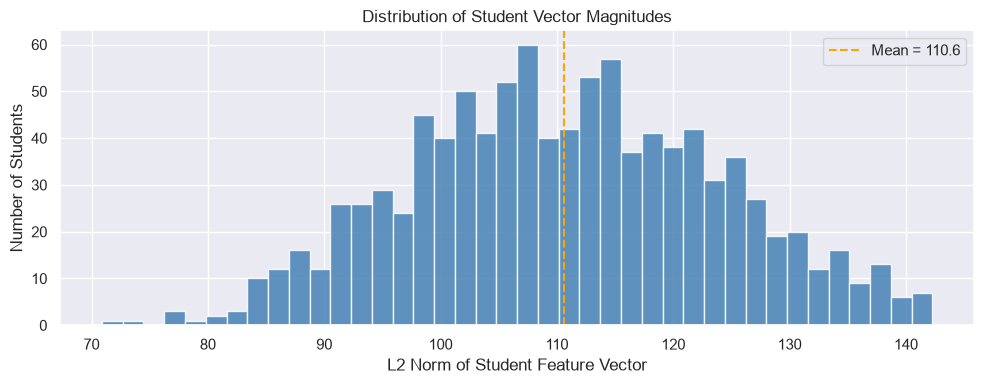

In [3]:
X = df_num.values
student_1 = X[0]
print("Student 1 feature vector:")
for col, val in zip(numeric_cols, student_1):
    print(f"  {col:<28} = {val:.2f}")

norms = np.linalg.norm(X, axis=1)
print(f"\nMean vector magnitude: {norms.mean():.2f}")

plt.figure(figsize=(10,4))
plt.hist(norms, bins=40, color="steelblue", edgecolor="white", alpha=0.85)
plt.axvline(norms.mean(), color="orange", linestyle="--",
            label=f"Mean = {norms.mean():.1f}")
plt.xlabel("L2 Norm of Student Feature Vector")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Vector Magnitudes")
plt.legend()
plt.tight_layout()
plt.show()

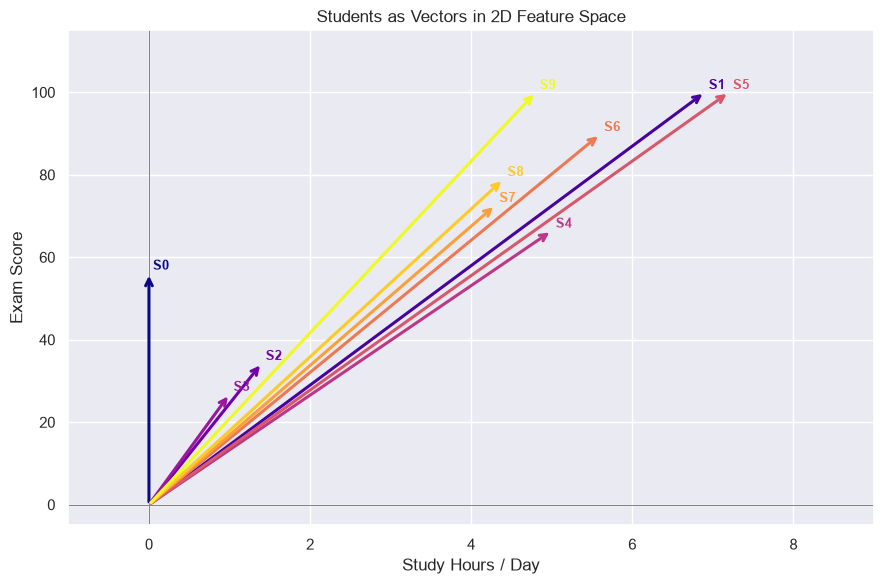

In [4]:
fig, ax = plt.subplots(figsize=(9,6))
sample = df_num[["study_hours_per_day","exam_score"]].iloc[:10].values
colors = plt.cm.plasma(np.linspace(0,1,len(sample)))
for i,(vec,color) in enumerate(zip(sample,colors)):
    ax.annotate("", xy=vec, xytext=(0,0),
                arrowprops=dict(arrowstyle="->", color=color, lw=2.2))
    ax.text(vec[0]+0.05, vec[1]+0.8, f"S{i}",
            fontsize=9, color=color, fontweight="bold")
ax.set_xlabel("Study Hours / Day")
ax.set_ylabel("Exam Score")
ax.set_title("Students as Vectors in 2D Feature Space")
ax.set_xlim(-1,9); ax.set_ylim(-5,115)
ax.axhline(0, color="gray", lw=0.7)
ax.axvline(0, color="gray", lw=0.7)
plt.tight_layout(); plt.show()

---
## 2. Matrices — Dataset as a Matrix

The dataset is a matrix $X$ of shape $(1000 \times 8)$.

$$\text{Cov} = \frac{1}{n}X^TX$$

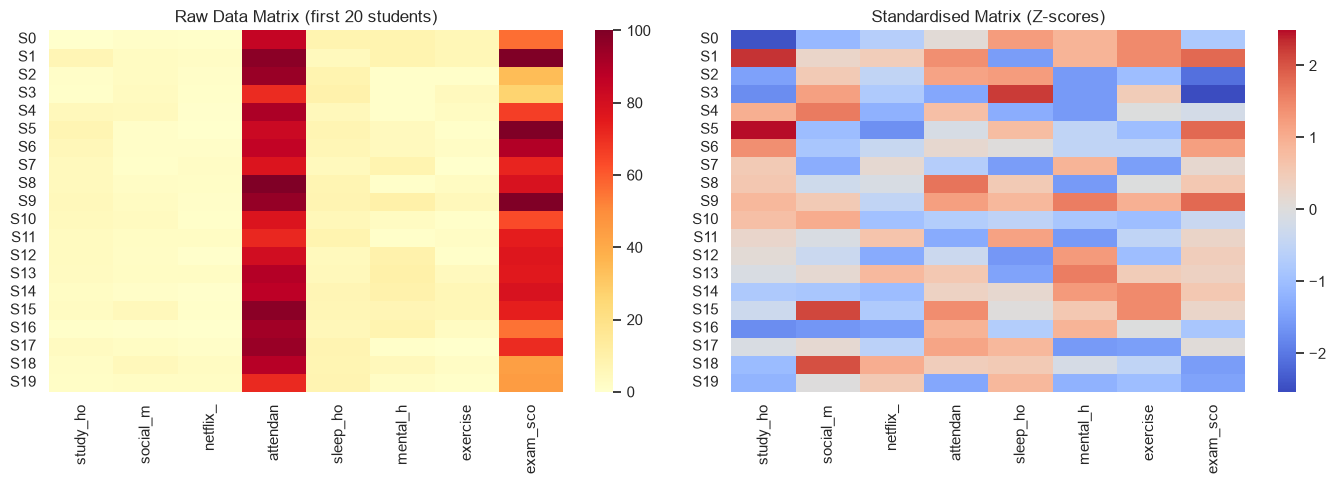

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
n = X_scaled.shape[0]
cov_matrix = (X_scaled.T @ X_scaled) / n

fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.heatmap(X[:20], ax=axes[0], cmap="YlOrRd",
            yticklabels=[f"S{i}" for i in range(20)],
            xticklabels=[c[:8] for c in numeric_cols])
axes[0].set_title("Raw Data Matrix (first 20 students)")

sns.heatmap(X_scaled[:20], ax=axes[1], cmap="coolwarm", center=0,
            yticklabels=[f"S{i}" for i in range(20)],
            xticklabels=[c[:8] for c in numeric_cols])
axes[1].set_title("Standardised Matrix (Z-scores)")
plt.tight_layout(); plt.show()

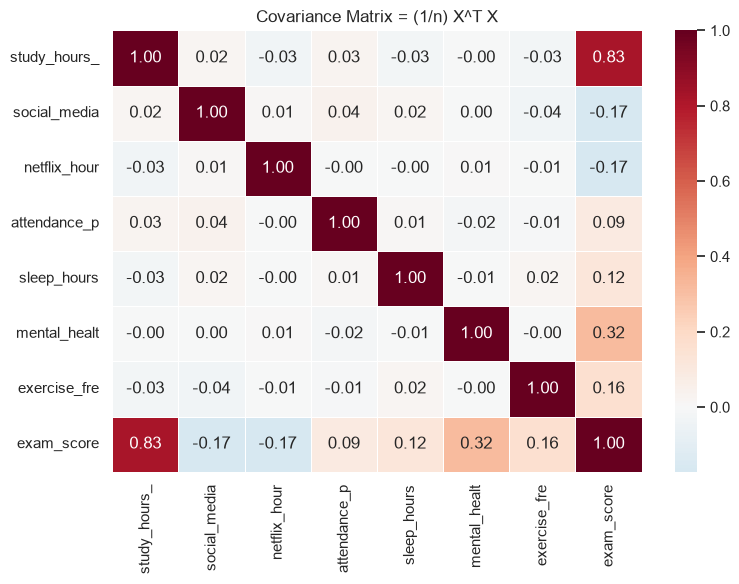

Diagonal = variance = 1.0 | Off-diagonal = covariance between features


In [6]:
plt.figure(figsize=(8,6))
sns.heatmap(pd.DataFrame(cov_matrix,
            index=[c[:12] for c in numeric_cols],
            columns=[c[:12] for c in numeric_cols]),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Covariance Matrix = (1/n) X^T X")
plt.tight_layout(); plt.show()
print("Diagonal = variance = 1.0 | Off-diagonal = covariance between features")

---
## 3. Dot Product — Similarity and Linear Prediction

$$\vec{a}\cdot\vec{b} = \sum_i a_i b_i = \|\vec{a}\|\|\vec{b}\|\cos\theta$$

- **Cosine similarity**: normalised dot product
- **Linear prediction**: $\hat{y} = \vec{w} \cdot \vec{x}$

Cosine Sim  S1 & S2 = -0.4469  (angle = 116.5 deg)
Cosine Sim  S1 & S3 = 0.2884  (angle = 73.2 deg)


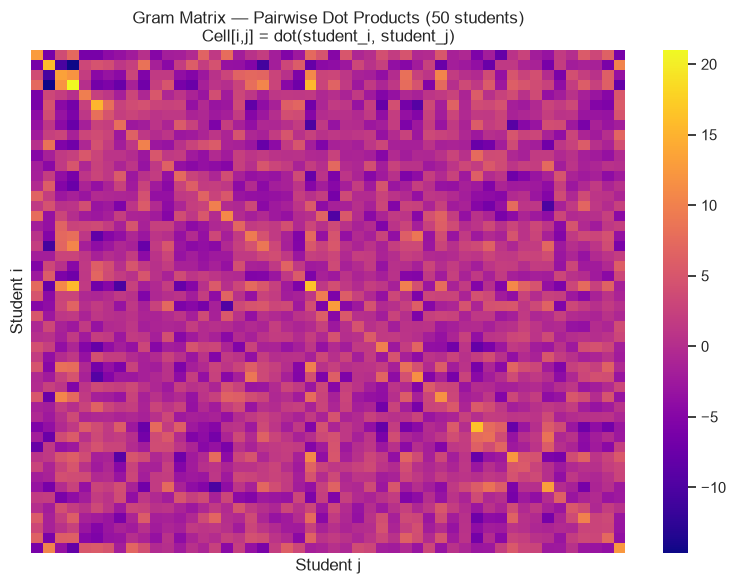

In [7]:
s1, s2, s3 = X_scaled[0], X_scaled[1], X_scaled[2]

def cosine_sim(a, b):
    return np.dot(a,b) / (np.linalg.norm(a) * np.linalg.norm(b))

cos_12 = cosine_sim(s1, s2)
cos_13 = cosine_sim(s1, s3)
print(f"Cosine Sim  S1 & S2 = {cos_12:.4f}  (angle = {np.degrees(np.arccos(np.clip(cos_12,-1,1))):.1f} deg)")
print(f"Cosine Sim  S1 & S3 = {cos_13:.4f}  (angle = {np.degrees(np.arccos(np.clip(cos_13,-1,1))):.1f} deg)")

subset = X_scaled[:50]
gram = subset @ subset.T
plt.figure(figsize=(8,6))
sns.heatmap(gram, cmap="plasma", xticklabels=False, yticklabels=False)
plt.title("Gram Matrix — Pairwise Dot Products (50 students)\nCell[i,j] = dot(student_i, student_j)")
plt.xlabel("Student j"); plt.ylabel("Student i")
plt.tight_layout(); plt.show()

Weight vector (intuitive prior):
  study_hours_per_day           w = +3.0
  social_media_hours            w = -1.0
  netflix_hours                 w = -0.5
  attendance_percentage         w = +0.5
  sleep_hours                   w = +0.2
  mental_health_rating          w = +0.3
  exercise_frequency            w = +0.1


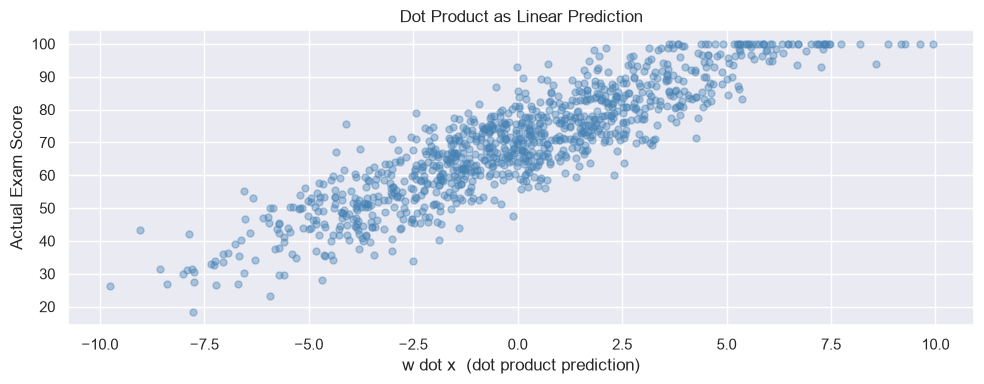

In [8]:
feature_cols = numeric_cols[:-1]
weights = np.array([3.0,-1.0,-0.5,0.5,0.2,0.3,0.1])
X_feat = X_scaled[:,:-1]
y_true = df_num["exam_score"].values
y_pred = X_feat @ weights

print("Weight vector (intuitive prior):")
for col,w in zip(feature_cols,weights):
    print(f"  {col:<28}  w = {w:+.1f}")

plt.figure(figsize=(10,4))
plt.scatter(y_pred, y_true, alpha=0.4, c="steelblue", s=25)
plt.xlabel("w dot x  (dot product prediction)")
plt.ylabel("Actual Exam Score")
plt.title("Dot Product as Linear Prediction")
plt.tight_layout(); plt.show()

---
## 4. Eigenvalues and Eigenvectors — PCA Intuition

$$C\vec{v} = \lambda\vec{v}$$

- $\vec{v}$ = eigenvector = principal component direction
- $\lambda$ = eigenvalue = variance explained in that direction

In [9]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[idx], eigenvectors[:,idx]
total_var = eigenvalues.sum()
exp_var = eigenvalues / total_var * 100
cum_var = np.cumsum(exp_var)

print("Eigenvalue Decomposition of Covariance Matrix:")
for i,(ev,pct,cum) in enumerate(zip(eigenvalues,exp_var,cum_var)):
    print(f"  PC{i+1}: lambda={ev:.4f} -> {pct:.1f}%  (cumulative {cum:.1f}%)")

v1, lam1 = eigenvectors[:,0], eigenvalues[0]
print(f"\nVerify Av=lv: max diff = {np.abs(cov_matrix@v1 - lam1*v1).max():.2e}  (should be ~0)")

Eigenvalue Decomposition of Covariance Matrix:
  PC1: lambda=1.9399 -> 24.2%  (cumulative 24.2%)
  PC2: lambda=1.0769 -> 13.5%  (cumulative 37.7%)
  PC3: lambda=1.0327 -> 12.9%  (cumulative 50.6%)
  PC4: lambda=1.0171 -> 12.7%  (cumulative 63.3%)
  PC5: lambda=0.9795 -> 12.2%  (cumulative 75.6%)
  PC6: lambda=0.9616 -> 12.0%  (cumulative 87.6%)
  PC7: lambda=0.9419 -> 11.8%  (cumulative 99.4%)
  PC8: lambda=0.0504 -> 0.6%  (cumulative 100.0%)

Verify Av=lv: max diff = 6.66e-16  (should be ~0)


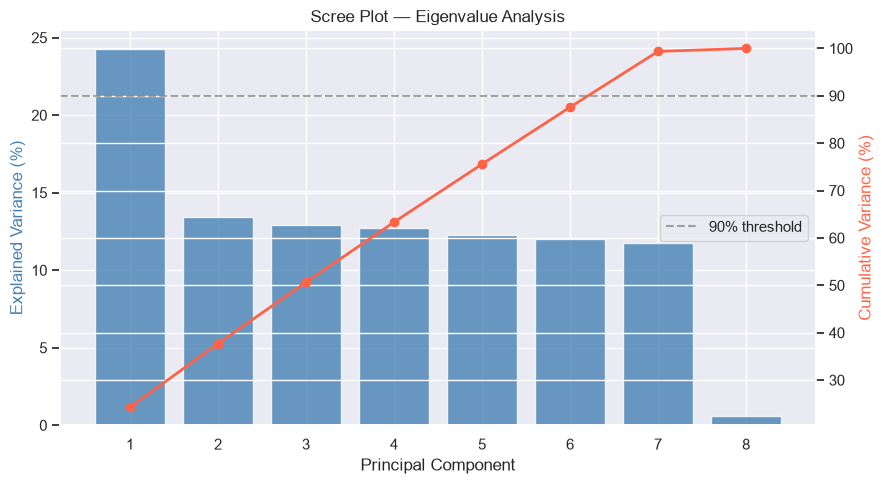

7 PCs explain >= 90% of total variance


In [10]:
fig, ax1 = plt.subplots(figsize=(9,5))
ax1.bar(range(1,len(eigenvalues)+1), exp_var, color="steelblue", alpha=0.8)
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance (%)", color="steelblue")
ax1.set_title("Scree Plot — Eigenvalue Analysis")
ax2 = ax1.twinx()
ax2.plot(range(1,len(eigenvalues)+1), cum_var, "o-", color="tomato", lw=2)
ax2.axhline(90, color="gray", linestyle="--", alpha=0.7, label="90% threshold")
ax2.set_ylabel("Cumulative Variance (%)", color="tomato")
ax2.legend(loc="center right")
plt.tight_layout(); plt.show()
n90 = np.argmax(cum_var >= 90) + 1
print(f"{n90} PCs explain >= 90% of total variance")

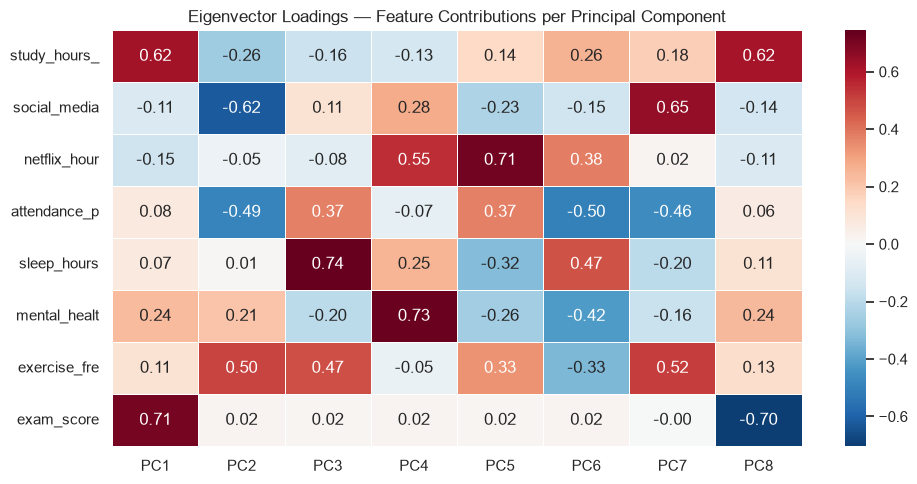

In [11]:
loadings_df = pd.DataFrame(eigenvectors,
    index=[c[:12] for c in numeric_cols],
    columns=[f"PC{i+1}" for i in range(len(eigenvalues))])
plt.figure(figsize=(10,5))
sns.heatmap(loadings_df, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Eigenvector Loadings — Feature Contributions per Principal Component")
plt.tight_layout(); plt.show()

Original: (1000, 8)  -->  PCA: (1000, 2)


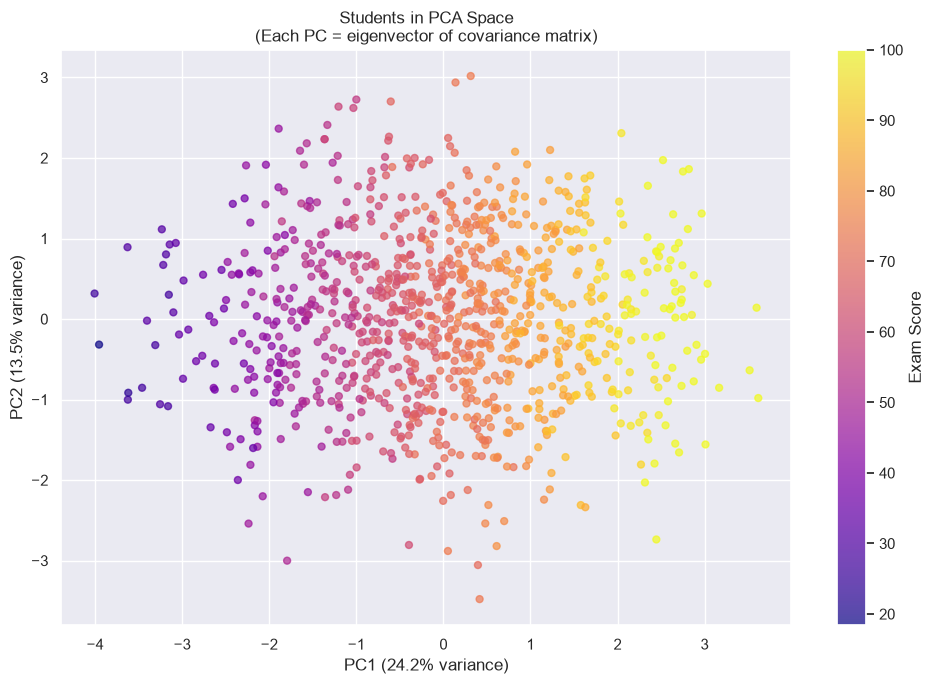

In [12]:
W = eigenvectors[:,:2]
X_pca = X_scaled @ W
print(f"Original: {X_scaled.shape}  -->  PCA: {X_pca.shape}")

plt.figure(figsize=(10,7))
sc = plt.scatter(X_pca[:,0], X_pca[:,1], c=y_true, cmap="plasma", alpha=0.7, s=25)
plt.colorbar(sc, label="Exam Score")
plt.xlabel(f"PC1 ({exp_var[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({exp_var[1]:.1f}% variance)")
plt.title("Students in PCA Space\n(Each PC = eigenvector of covariance matrix)")
plt.tight_layout(); plt.show()

---
## Summary — Linear Algebra in ML

| Concept | Formula | Applied |
|---|---|---|
| **Vector** | $\vec{s} \in \mathbb{R}^d$ | Student = 8D feature vector |
| **Matrix** | $X \in \mathbb{R}^{n\times d}$ | Dataset = 1000×8 |
| **Covariance** | $(1/n)X^TX$ | Feature relationships |
| **Dot Product** | $\vec{a}\cdot\vec{b}$ | Similarity + linear prediction |
| **Eigenvalue** | $C\vec{v}=\lambda\vec{v}$ | Variance per direction |
| **PCA** | $X_{pca}=X\cdot W$ | 8D → 2D compression |

> **Key Insight**: PCA = eigendecomposition of covariance matrix. Everything is matrix operations!